In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("No GPU detected. Check Runtime settings.")


PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4
GPU memory (GB): 15.64


In [2]:

!pip -q install datasets tiktoken matplotlib pandas


In [3]:

from datasets import load_dataset

dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

print("Number of stories:", len(dataset))
print("\nFirst story:\n")
print(dataset[0]["text"][:1000])


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

...

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Number of stories: 1000

First story:

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.


In [4]:

import tiktoken

# Load GPT-2 tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

# Test tokenization
sample_text = dataset[0]["text"]

token_ids = tokenizer.encode(sample_text)

print("Original text:")
print(sample_text[:200])

print("\nFirst 30 token IDs:")
print(token_ids[:30])

print("\nTotal tokens in this story:", len(token_ids))
print("Vocabulary size:", tokenizer.n_vocab)


Original text:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on

First 30 token IDs:
[3198, 1110, 11, 257, 1310, 2576, 3706, 20037, 1043, 257, 17598, 287, 607, 2119, 13, 1375, 2993, 340, 373, 2408, 284, 711, 351, 340, 780, 340, 373, 7786, 13, 20037]

Total tokens in this story: 162
Vocabulary size: 50257


In [5]:

import torch

# Keep a fixed sequence length for our first experiment
block_size = 128

# Encode the stories separately
train_ids = [
    tokenizer.encode(text)
    for text in dataset["text"]
]

# Join token IDs into one continuous stream
all_tokens = [
    token
    for story in train_ids
    for token in story + [tokenizer.eot_token]
]

data = torch.tensor(all_tokens, dtype=torch.long)

print("Total tokens:", len(data))
print("Sequence length:", block_size)
print("Number of complete sequences:", len(data) // block_size)


Total tokens: 235420
Sequence length: 128
Number of complete sequences: 1839


In [6]:

batch_size = 16

def get_batch(data, batch_size=16, block_size=128):
    starts = torch.randint(
        0,
        len(data) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size]
        for i in starts
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1]
        for i in starts
    ])

    return x, y

x, y = get_batch(data)

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("First input sequence:", x[0][:10].tolist())
print("First target sequence:", y[0][:10].tolist())


Input shape: torch.Size([16, 128])
Target shape: torch.Size([16, 128])
First input sequence: [6497, 683, 510, 13, 1375, 41130, 683, 290, 531, 11]
First target sequence: [683, 510, 13, 1375, 41130, 683, 290, 531, 11, 366]


In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Model configuration
vocab_size = tokenizer.n_vocab
block_size = 128
n_embd = 128
n_head = 4
n_layer = 4
dropout = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=n_embd,
            num_heads=n_head,
            dropout=dropout,
            batch_first=True
        )

    def forward(self, x):
        T = x.size(1)

        # Prevent a token from seeing future tokens
        mask = torch.triu(
            torch.ones(T, T, device=x.device, dtype=torch.bool),
            diagonal=1
        )

        out, _ = self.attention(
            x, x, x,
            attn_mask=mask,
            need_weights=False
        )
        return out


class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention()
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward()

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x


class DenseGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)

        self.blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(n_layer)]
        )

        self.final_ln = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok = self.token_embedding(idx)
        pos = self.position_embedding(
            torch.arange(T, device=idx.device)
        )

        x = tok + pos
        x = self.blocks(x)
        x = self.final_ln(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1)
            )

        return logits, loss


device = "cuda" if torch.cuda.is_available() else "cpu"

model = DenseGPT().to(device)

print("Model created successfully!")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))


NameError: name 'tokenizer' is not defined

In [2]:

import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.n_vocab)


Tokenizer loaded successfully!
Vocabulary size: 50257


In [3]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Model configuration
vocab_size = tokenizer.n_vocab
block_size = 128
n_embd = 128
n_head = 4
n_layer = 4
dropout = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=n_embd,
            num_heads=n_head,
            dropout=dropout,
            batch_first=True
        )

    def forward(self, x):
        T = x.size(1)

        # Prevent a token from seeing future tokens
        mask = torch.triu(
            torch.ones(T, T, device=x.device, dtype=torch.bool),
            diagonal=1
        )

        out, _ = self.attention(
            x, x, x,
            attn_mask=mask,
            need_weights=False
        )
        return out


class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention()
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward()

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x


class DenseGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)

        self.blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(n_layer)]
        )

        self.final_ln = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok = self.token_embedding(idx)
        pos = self.position_embedding(
            torch.arange(T, device=idx.device)
        )

        x = tok + pos
        x = self.blocks(x)
        x = self.final_ln(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1)
            )

        return logits, loss


device = "cuda" if torch.cuda.is_available() else "cpu"

model = DenseGPT().to(device)

print("Model created successfully!")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))


Model created successfully!
Device: cuda
Parameters: 13725777


In [4]:

model.eval()

with torch.no_grad():
    x_test, y_test = get_batch(data, batch_size=2, block_size=128)
    x_test = x_test.to(device)
    y_test = y_test.to(device)

    logits, loss = model(x_test, y_test)

print("Input shape:", x_test.shape)
print("Output logits shape:", logits.shape)
print("Initial loss:", loss.item())


NameError: name 'get_batch' is not defined

In [5]:

import torch

block_size = 128
batch_size = 16

def get_batch(data, batch_size=16, block_size=128):
    starts = torch.randint(
        0,
        len(data) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size]
        for i in starts
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1]
        for i in starts
    ])

    return x, y

print("get_batch function is ready!")


get_batch function is ready!


In [6]:

model.eval()

with torch.no_grad():
    x_test, y_test = get_batch(
        data,
        batch_size=2,
        block_size=128
    )

    x_test = x_test.to(device)
    y_test = y_test.to(device)

    logits, loss = model(x_test, y_test)

print("Input shape:", x_test.shape)
print("Output logits shape:", logits.shape)
print("Initial loss:", loss.item())


NameError: name 'data' is not defined

In [7]:

import torch
import tiktoken
from datasets import load_dataset

# 1. Load tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

# 2. Load 1,000 TinyStories
dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

# 3. Tokenize stories and preserve story boundaries
all_tokens = []

for story in dataset["text"]:
    all_tokens.extend(tokenizer.encode(story))
    all_tokens.append(tokenizer.eot_token)

# 4. Create token tensor
data = torch.tensor(all_tokens, dtype=torch.long)

# 5. Define batch function
def get_batch(data, batch_size=16, block_size=128):
    starts = torch.randint(
        len(data) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size] for i in starts
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1] for i in starts
    ])

    return x, y

print("Tokenizer ready:", tokenizer.n_vocab)
print("Stories loaded:", len(dataset))
print("Total tokens:", len(data))

x_test, y_test = get_batch(data, batch_size=2, block_size=128)

print("Input shape:", x_test.shape)
print("Target shape:", y_test.shape)
print("Data pipeline ready!")


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

...

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Tokenizer ready: 50257
Stories loaded: 1000
Total tokens: 235420
Input shape: torch.Size([2, 128])
Target shape: torch.Size([2, 128])
Data pipeline ready!


In [8]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Configuration
vocab_size = tokenizer.n_vocab
block_size = 128
n_embd = 128
n_head = 4
n_layer = 4
dropout = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            n_embd, n_head,
            dropout=dropout,
            batch_first=True
        )

    def forward(self, x):
        T = x.size(1)

        mask = torch.triu(
            torch.ones(T, T, device=x.device, dtype=torch.bool),
            diagonal=1
        )

        out, _ = self.attention(
            x, x, x,
            attn_mask=mask,
            need_weights=False
        )
        return out


class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention()
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward()

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x


class DenseGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)

        self.blocks = nn.Sequential(
            *[TransformerBlock() for _ in range(n_layer)]
        )

        self.final_ln = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok = self.token_embedding(idx)
        pos = self.position_embedding(
            torch.arange(T, device=idx.device)
        )

        x = tok + pos
        x = self.blocks(x)
        x = self.final_ln(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1)
            )

        return logits, loss


device = "cuda" if torch.cuda.is_available() else "cpu"

model = DenseGPT().to(device)

print("Dense GPT created successfully!")
print("Device:", device)
print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)


Dense GPT created successfully!
Device: cuda
Parameters: 13725777


In [9]:

model.eval()

with torch.no_grad():
    x_test, y_test = get_batch(
        data, batch_size=2, block_size=128
    )

    x_test = x_test.to(device)
    y_test = y_test.to(device)

    logits, loss = model(x_test, y_test)

print("Input shape:", x_test.shape)
print("Output logits shape:", logits.shape)
print("Initial loss:", loss.item())


Input shape: torch.Size([2, 128])
Output logits shape: torch.Size([2, 128, 50257])
Initial loss: 10.988388061523438


In [10]:

import torch

# Use the 1,000 stories already loaded
train_stories = dataset["text"][:900]
val_stories = dataset["text"][900:1000]

def encode_stories(stories):
    tokens = []
    for story in stories:
        tokens.extend(tokenizer.encode(story))
        tokens.append(tokenizer.eot_token)
    return torch.tensor(tokens, dtype=torch.long)

train_data = encode_stories(train_stories)
val_data = encode_stories(val_stories)

print("Training stories:", len(train_stories))
print("Validation stories:", len(val_stories))
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))


Training stories: 900
Validation stories: 100
Training tokens: 193192
Validation tokens: 42228


In [11]:

import time
import torch
import torch.nn.functional as F

torch.manual_seed(42)

batch_size = 8
block_size = 128
max_iters = 500
eval_interval = 100
learning_rate = 3e-4

# Sample input and next-token targets
def get_batch_from(source, batch_size=8):
    starts = torch.randint(
        0, len(source) - block_size - 1, (batch_size,)
    )
    x = torch.stack([
        source[i:i + block_size] for i in starts
    ])
    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in starts
    ])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}

    for name, source in [
        ("train", train_data),
        ("val", val_data)
    ]:
        losses = []
        for _ in range(10):
            xb, yb = get_batch_from(source)
            _, loss = model(xb, yb)
            losses.append(loss.item())
        results[name] = sum(losses) / len(losses)

    model.train()
    return results

optimizer = torch.optim.AdamW(
    model.parameters(), lr=learning_rate
)

history = {"step": [], "train_loss": [], "val_loss": []}
start_time = time.time()

model.train()

for step in range(1, max_iters + 1):
    xb, yb = get_batch_from(train_data)

    optimizer.zero_grad(set_to_none=True)
    _, loss = model(xb, yb)
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(), 1.0
    )
    optimizer.step()

    if step % eval_interval == 0 or step == 1:
        scores = estimate_loss()

        history["step"].append(step)
        history["train_loss"].append(scores["train"])
        history["val_loss"].append(scores["val"])

        print(
            f"Step {step:4d}/{max_iters} | "
            f"Train loss: {scores['train']:.4f} | "
            f"Val loss: {scores['val']:.4f}"
        )

print(f"Training time: {(time.time()-start_time)/60:.2f} minutes")

torch.save(model.state_dict(), "dense_gpt.pt")
print("Dense GPT checkpoint saved!")


Step    1/500 | Train loss: 10.9393 | Val loss: 10.9400
Step  100/500 | Train loss: 6.0999 | Val loss: 6.0546
Step  200/500 | Train loss: 5.5966 | Val loss: 5.5305
Step  300/500 | Train loss: 5.2075 | Val loss: 5.1641
Step  400/500 | Train loss: 4.8584 | Val loss: 5.0479
Step  500/500 | Train loss: 4.6389 | Val loss: 4.8503
Training time: 0.28 minutes
Dense GPT checkpoint saved!


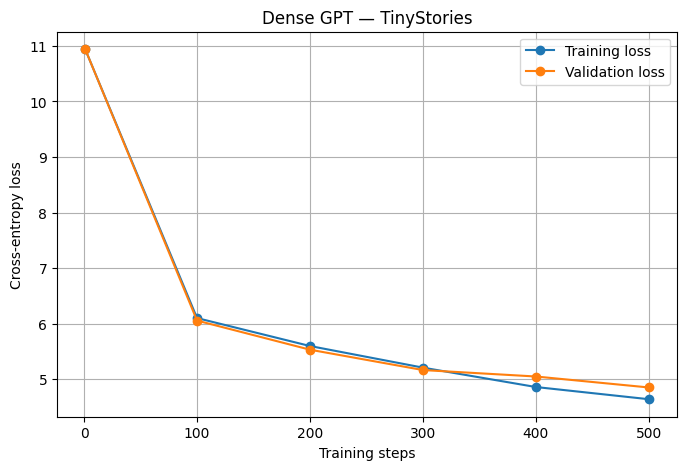

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["step"], history["train_loss"],
         marker="o", label="Training loss")
plt.plot(history["step"], history["val_loss"],
         marker="o", label="Validation loss")

plt.xlabel("Training steps")
plt.ylabel("Cross-entropy loss")
plt.title("Dense GPT — TinyStories")
plt.legend()
plt.grid(True)
plt.show()


In [13]:

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class MoEFeedForward(nn.Module):
    def __init__(
        self,
        n_embd=128,
        num_experts=4,
        capacity_factor=1.25,
        dropout=0.1
    ):
        super().__init__()

        self.num_experts = num_experts
        self.capacity_factor = capacity_factor

        # Router assigns each token to an expert.
        self.router = nn.Linear(n_embd, num_experts, bias=False)

        # Every expert has its own independent FFN.
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(n_embd, 4 * n_embd),
                nn.GELU(),
                nn.Linear(4 * n_embd, n_embd),
                nn.Dropout(dropout)
            )
            for _ in range(num_experts)
        ])

    def forward(self, x):
        # x shape: [batch, sequence, embedding]
        B, T, D = x.shape
        tokens = x.reshape(B * T, D)
        total_tokens = tokens.size(0)
        N = self.num_experts

        # Router probabilities for every token.
        router_logits = self.router(tokens).float()
        router_probs = F.softmax(router_logits, dim=-1)

        # Top-1 routing: one expert per token.
        gates, expert_ids = router_probs.max(dim=-1)

        # Capacity limit for each expert.
        capacity = max(
            1,
            math.ceil(
                (total_tokens / N) * self.capacity_factor
            )
        )

        # Encourage balanced routing.
        importance = router_probs.mean(dim=0)

        fraction_routed = F.one_hot(
            expert_ids, num_classes=N
        ).float().mean(dim=0)

        balance_loss = N * torch.sum(
            importance * fraction_routed
        )

        # Initially, outputs for all tokens are zero.
        # Overflow tokens retain the residual path in the block.
        output = torch.zeros_like(tokens)

        routed_counts = torch.bincount(
            expert_ids, minlength=N
        )
        accepted_counts = torch.zeros(
            N, dtype=torch.long, device=x.device
        )

        # Run each expert only on its accepted tokens.
        for expert_idx in range(N):
            selected = torch.where(
                expert_ids == expert_idx
            )[0]

            # Enforce capacity using deterministic token order.
            accepted = selected[:capacity]
            accepted_counts[expert_idx] = accepted.numel()

            if accepted.numel() == 0:
                continue

            expert_input = tokens[accepted]
            expert_output = self.experts[expert_idx](
                expert_input
            )

            # Scale each expert output by its router probability.
            expert_output = expert_output * gates[
                accepted
            ].unsqueeze(-1)

            output = output.index_copy(
                0, accepted, expert_output
            )

        dropped_tokens = (
            routed_counts - accepted_counts
        ).sum()

        stats = {
            "capacity": capacity,
            "routed_counts": routed_counts.detach(),
            "accepted_counts": accepted_counts.detach(),
            "dropped_tokens": dropped_tokens.detach(),
            "total_tokens": total_tokens
        }

        return output.reshape(B, T, D), balance_loss, stats


# Test the MoE FFN independently.
moe_ffn = MoEFeedForward(
    n_embd=128,
    num_experts=4,
    capacity_factor=1.25
).to(device)

test_input = torch.randn(2, 128, 128, device=device)

test_output, aux_loss, stats = moe_ffn(test_input)

print("Input shape:", test_input.shape)
print("MoE output shape:", test_output.shape)
print("Number of experts:", moe_ffn.num_experts)
print("Expert capacity:", stats["capacity"])
print("Routed tokens:", stats["routed_counts"].tolist())
print("Accepted tokens:", stats["accepted_counts"].tolist())
print("Dropped tokens:", stats["dropped_tokens"].item())
print("Balance loss:", aux_loss.item())


Input shape: torch.Size([2, 128, 128])
MoE output shape: torch.Size([2, 128, 128])
Number of experts: 4
Expert capacity: 80
Routed tokens: [68, 56, 67, 65]
Accepted tokens: [68, 56, 67, 65]
Dropped tokens: 0
Balance loss: 1.0010206699371338


In [14]:

# Build a GPT whose FFN layers use top-1 MoE.
# Requires the MoEFeedForward class from the previous cell.

class MoETransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()

        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention()

        self.ln2 = nn.LayerNorm(n_embd)
        self.moe_ffn = MoEFeedForward(
            n_embd=n_embd,
            num_experts=4,
            capacity_factor=1.25,
            dropout=dropout
        )

    def forward(self, x):
        # Same attention and residual connection as Dense GPT.
        x = x + self.attn(self.ln1(x))

        # Replace dense FFN with sparse MoE FFN.
        moe_output, aux_loss, stats = self.moe_ffn(
            self.ln2(x)
        )

        # Overflow tokens receive zero FFN output, so
        # their residual representation is preserved.
        x = x + moe_output

        return x, aux_loss, stats


class MoEGPT(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size, n_embd
        )
        self.position_embedding = nn.Embedding(
            block_size, n_embd
        )

        self.blocks = nn.ModuleList([
            MoETransformerBlock()
            for _ in range(n_layer)
        ])

        self.final_ln = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok = self.token_embedding(idx)
        pos = self.position_embedding(
            torch.arange(T, device=idx.device)
        )

        x = tok + pos

        aux_losses = []
        all_stats = []

        for block in self.blocks:
            x, aux_loss, stats = block(x)
            aux_losses.append(aux_loss)
            all_stats.append(stats)

        x = self.final_ln(x)
        logits = self.lm_head(x)

        lm_loss = None

        if targets is not None:
            lm_loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1)
            )

        # Average auxiliary loss across MoE layers.
        aux_loss = torch.stack(aux_losses).mean()

        return logits, lm_loss, aux_loss, all_stats


# Create a separate model; preserve the Dense GPT baseline.
moe_model = MoEGPT().to(device)

print("MoE GPT created successfully!")
print("Device:", device)
print(
    "MoE GPT parameters:",
    sum(p.numel() for p in moe_model.parameters())
)
print("MoE layers:", len(moe_model.blocks))
print("Experts per layer:", 4)


MoE GPT created successfully!
Device: cuda
MoE GPT parameters: 15308369
MoE layers: 4
Experts per layer: 4


In [15]:

moe_model.eval()

with torch.no_grad():
    x_test, y_test = get_batch(
        data, batch_size=2, block_size=128
    )

    x_test = x_test.to(device)
    y_test = y_test.to(device)

    logits, lm_loss, aux_loss, all_stats = moe_model(
        x_test, y_test
    )

print("Input shape:", x_test.shape)
print("Logits shape:", logits.shape)
print("Language-model loss:", lm_loss.item())
print("Auxiliary balancing loss:", aux_loss.item())

for layer_idx, stats in enumerate(all_stats):
    print(f"\nMoE layer {layer_idx + 1}")
    print("Capacity:", stats["capacity"])
    print("Routed:", stats["routed_counts"].tolist())
    print("Accepted:", stats["accepted_counts"].tolist())
    print("Dropped:", stats["dropped_tokens"].item())


Input shape: torch.Size([2, 128])
Logits shape: torch.Size([2, 128, 50257])
Language-model loss: 10.934348106384277
Auxiliary balancing loss: 1.0084795951843262

MoE layer 1
Capacity: 80
Routed: [68, 59, 64, 65]
Accepted: [68, 59, 64, 65]
Dropped: 0

MoE layer 2
Capacity: 80
Routed: [79, 53, 61, 63]
Accepted: [79, 53, 61, 63]
Dropped: 0

MoE layer 3
Capacity: 80
Routed: [84, 54, 56, 62]
Accepted: [80, 54, 56, 62]
Dropped: 4

MoE layer 4
Capacity: 80
Routed: [80, 45, 84, 47]
Accepted: [80, 45, 80, 47]
Dropped: 4


In [16]:

import time
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Training configuration: match the dense baseline.
moe_batch_size = 8
moe_steps = 500
eval_interval = 100
learning_rate = 3e-4
aux_coefficient = 0.01

# A separate optimizer for the MoE model.
moe_optimizer = torch.optim.AdamW(
    moe_model.parameters(),
    lr=learning_rate
)

moe_history = {
    "step": [],
    "train_loss": [],
    "val_loss": [],
    "balance_loss": [],
    "total_loss": []
}

@torch.no_grad()
def evaluate_moe():
    moe_model.eval()

    train_lm_losses = []
    val_lm_losses = []
    balance_losses = []

    for _ in range(10):
        xb, yb = get_batch_from(
            train_data, moe_batch_size
        )
        _, lm_loss, aux_loss, _ = moe_model(xb, yb)

        train_lm_losses.append(lm_loss.item())
        balance_losses.append(aux_loss.item())

        xb, yb = get_batch_from(
            val_data, moe_batch_size
        )
        _, val_loss, _, _ = moe_model(xb, yb)
        val_lm_losses.append(val_loss.item())

    moe_model.train()

    return (
        sum(train_lm_losses) / len(train_lm_losses),
        sum(val_lm_losses) / len(val_lm_losses),
        sum(balance_losses) / len(balance_losses)
    )


moe_model.train()
start_time = time.time()

for step in range(1, moe_steps + 1):
    xb, yb = get_batch_from(
        train_data, moe_batch_size
    )

    # Forward pass through GPT and its MoE layers.
    _, lm_loss, aux_loss, _ = moe_model(xb, yb)

    # Main language-model objective + balancing objective.
    total_loss = lm_loss + aux_coefficient * aux_loss

    moe_optimizer.zero_grad(set_to_none=True)
    total_loss.backward()

    torch.nn.utils.clip_grad_norm_(
        moe_model.parameters(), 1.0
    )

    moe_optimizer.step()

    if step % eval_interval == 0 or step == 1:
        train_lm, val_lm, balance = evaluate_moe()

        moe_history["step"].append(step)
        moe_history["train_loss"].append(train_lm)
        moe_history["val_loss"].append(val_lm)
        moe_history["balance_loss"].append(balance)
        moe_history["total_loss"].append(
            train_lm + aux_coefficient * balance
        )

        print(
            f"Step {step:4d}/{moe_steps} | "
            f"Train LM: {train_lm:.4f} | "
            f"Val LM: {val_lm:.4f} | "
            f"Balance: {balance:.4f}"
        )

print(
    f"\nMoE training time: "
    f"{(time.time() - start_time) / 60:.2f} minutes"
)

torch.save(
    moe_model.state_dict(),
    "moe_gpt.pt"
)

print("MoE GPT checkpoint saved!")


Step    1/500 | Train LM: 10.9744 | Val LM: 10.9743 | Balance: 1.0090
Step  100/500 | Train LM: 6.1533 | Val LM: 6.2061 | Balance: 1.3412
Step  200/500 | Train LM: 5.6283 | Val LM: 5.6738 | Balance: 1.1096
Step  300/500 | Train LM: 5.1999 | Val LM: 5.3070 | Balance: 1.0706
Step  400/500 | Train LM: 4.9343 | Val LM: 5.0872 | Balance: 1.0792
Step  500/500 | Train LM: 4.7694 | Val LM: 4.7920 | Balance: 1.0630

MoE training time: 0.38 minutes
MoE GPT checkpoint saved!


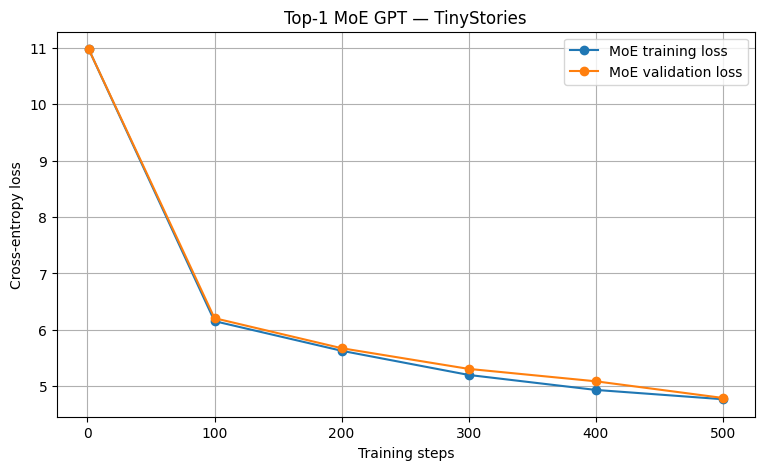

In [17]:

plt.figure(figsize=(9, 5))

plt.plot(
    moe_history["step"],
    moe_history["train_loss"],
    marker="o",
    label="MoE training loss"
)

plt.plot(
    moe_history["step"],
    moe_history["val_loss"],
    marker="o",
    label="MoE validation loss"
)

plt.xlabel("Training steps")
plt.ylabel("Cross-entropy loss")
plt.title("Top-1 MoE GPT — TinyStories")
plt.legend()
plt.grid(True)
plt.show()


In [18]:

import torch
import numpy as np
import matplotlib.pyplot as plt

num_layers = len(moe_model.blocks)
num_experts = 4
num_eval_batches = 100

routed_totals = np.zeros((num_layers, num_experts))
accepted_totals = np.zeros((num_layers, num_experts))
dropped_totals = np.zeros(num_layers)
token_totals = np.zeros(num_layers)

moe_model.eval()

with torch.no_grad():
    for _ in range(num_eval_batches):
        xb, yb = get_batch_from(train_data, batch_size=8)

        _, _, _, all_stats = moe_model(xb, yb)

        for layer_idx, stats in enumerate(all_stats):
            routed_totals[layer_idx] += (
                stats["routed_counts"].cpu().numpy()
            )
            accepted_totals[layer_idx] += (
                stats["accepted_counts"].cpu().numpy()
            )
            dropped_totals[layer_idx] += (
                stats["dropped_tokens"].item()
            )
            token_totals[layer_idx] += (
                stats["total_tokens"]
            )

print("Expert utilisation evaluation complete.")

for layer_idx in range(num_layers):
    print(f"\nLayer {layer_idx + 1}")
    print("Routed:", routed_totals[layer_idx].astype(int))
    print("Accepted:", accepted_totals[layer_idx].astype(int))
    print("Dropped:", int(dropped_totals[layer_idx]))


Expert utilisation evaluation complete.

Layer 1
Routed: [12375 31561 32024 26440]
Accepted: [12375 30989 31282 26440]
Dropped: 1314

Layer 2
Routed: [13141 32649 30889 25721]
Accepted: [13141 31660 30630 25721]
Dropped: 1248

Layer 3
Routed: [12715 37855 28080 23750]
Accepted: [12715 32000 28079 23750]
Dropped: 5856

Layer 4
Routed: [28204 22411 25190 26595]
Accepted: [28204 22411 25190 26595]
Dropped: 0


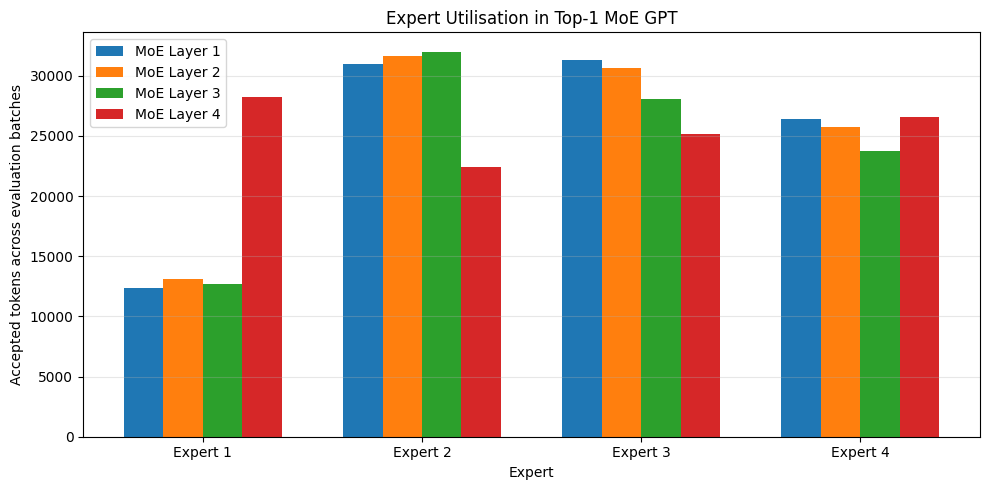

In [19]:

x = np.arange(num_experts)
width = 0.18

plt.figure(figsize=(10, 5))

for layer_idx in range(num_layers):
    plt.bar(
        x + (layer_idx - (num_layers - 1) / 2) * width,
        accepted_totals[layer_idx],
        width,
        label=f"MoE Layer {layer_idx + 1}"
    )

plt.xlabel("Expert")
plt.ylabel("Accepted tokens across evaluation batches")
plt.title("Expert Utilisation in Top-1 MoE GPT")
plt.xticks(x, [f"Expert {i+1}" for i in range(num_experts)])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

for layer_idx in range(num_layers):
    total_routed = routed_totals[layer_idx].sum()
    total_dropped = dropped_totals[layer_idx]

    overflow_rate = (
        100 * total_dropped / total_routed
        if total_routed > 0 else 0
    )

    print(
        f"Layer {layer_idx + 1}: "
        f"Dropped {int(total_dropped)} / "
        f"{int(total_routed)} routed tokens "
        f"({overflow_rate:.2f}%)"
    )


Layer 1: Dropped 1314 / 102400 routed tokens (1.28%)
Layer 2: Dropped 1248 / 102400 routed tokens (1.22%)
Layer 3: Dropped 5856 / 102400 routed tokens (5.72%)
Layer 4: Dropped 0 / 102400 routed tokens (0.00%)


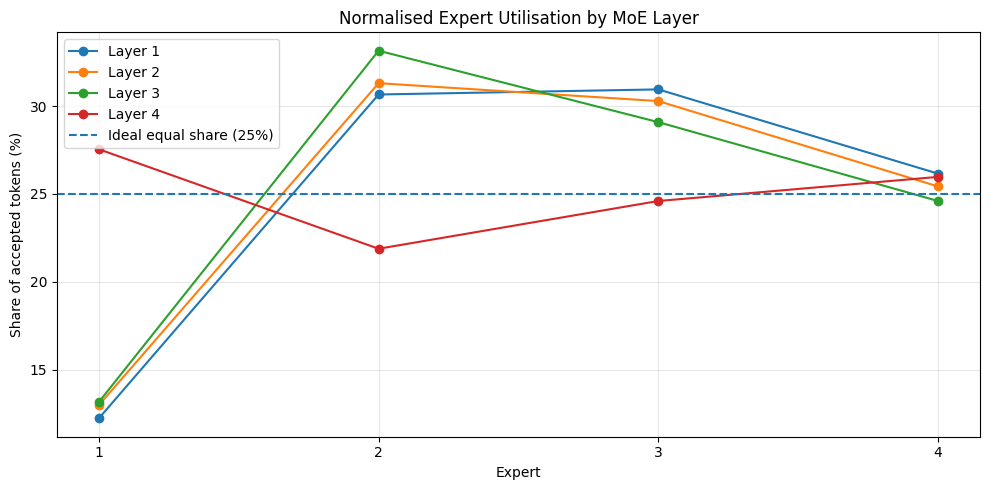

Utilisation percentages:
Layer 1: [12.24, 30.66, 30.95, 26.16]
Layer 2: [12.99, 31.3, 30.28, 25.43]
Layer 3: [13.17, 33.15, 29.08, 24.6]
Layer 4: [27.54, 21.89, 24.6, 25.97]


In [21]:

import numpy as np
import matplotlib.pyplot as plt

# Convert accepted token counts to percentages per layer.
utilisation_pct = (
    accepted_totals
    / accepted_totals.sum(axis=1, keepdims=True)
    * 100
)

plt.figure(figsize=(10, 5))

for layer_idx in range(num_layers):
    plt.plot(
        range(1, num_experts + 1),
        utilisation_pct[layer_idx],
        marker="o",
        label=f"Layer {layer_idx + 1}"
    )

plt.axhline(
    25, linestyle="--",
    label="Ideal equal share (25%)"
)

plt.xlabel("Expert")
plt.ylabel("Share of accepted tokens (%)")
plt.title("Normalised Expert Utilisation by MoE Layer")
plt.xticks(range(1, num_experts + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Utilisation percentages:")
for layer_idx in range(num_layers):
    print(
        f"Layer {layer_idx + 1}:",
        np.round(utilisation_pct[layer_idx], 2).tolist()
    )


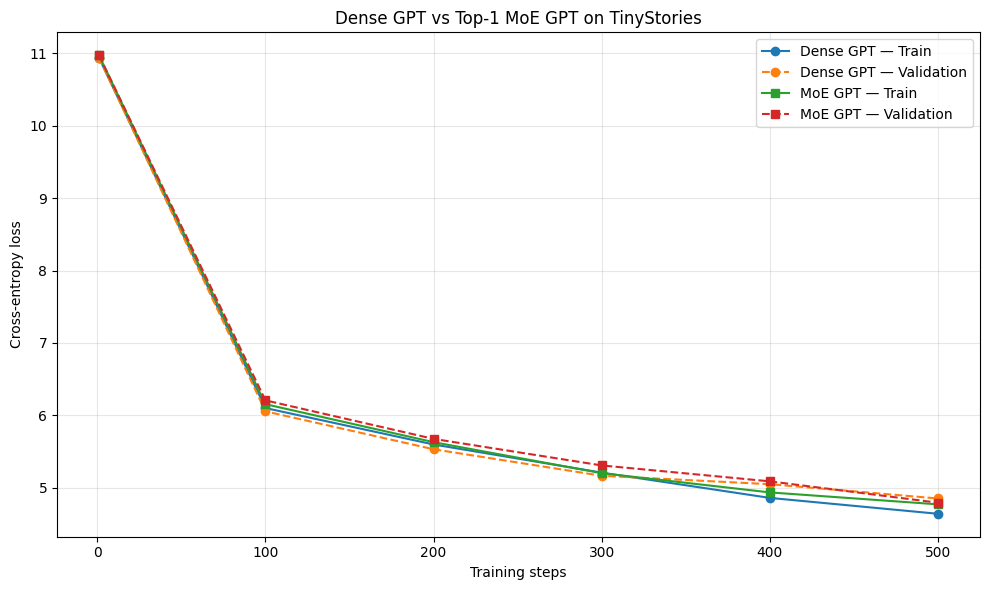

Dense final validation loss: 4.8503
MoE final validation loss: 4.792


In [22]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Dense GPT
plt.plot(
    history["step"],
    history["train_loss"],
    marker="o",
    label="Dense GPT — Train"
)

plt.plot(
    history["step"],
    history["val_loss"],
    marker="o",
    linestyle="--",
    label="Dense GPT — Validation"
)

# MoE GPT
plt.plot(
    moe_history["step"],
    moe_history["train_loss"],
    marker="s",
    label="MoE GPT — Train"
)

plt.plot(
    moe_history["step"],
    moe_history["val_loss"],
    marker="s",
    linestyle="--",
    label="MoE GPT — Validation"
)

plt.xlabel("Training steps")
plt.ylabel("Cross-entropy loss")
plt.title("Dense GPT vs Top-1 MoE GPT on TinyStories")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Dense final validation loss:",
      round(history["val_loss"][-1], 4))

print("MoE final validation loss:",
      round(moe_history["val_loss"][-1], 4))


In [23]:

import math
import pandas as pd

dense_val = history["val_loss"][-1]
moe_val = moe_history["val_loss"][-1]

dense_params = sum(
    p.numel() for p in model.parameters()
)
moe_params = sum(
    p.numel() for p in moe_model.parameters()
)

results = pd.DataFrame({
    "Metric": [
        "Final training loss",
        "Final validation loss",
        "Validation perplexity",
        "Total parameters"
    ],
    "Dense GPT": [
        history["train_loss"][-1],
        dense_val,
        math.exp(dense_val),
        dense_params
    ],
    "Top-1 MoE GPT": [
        moe_history["train_loss"][-1],
        moe_val,
        math.exp(moe_val),
        moe_params
    ]
})

print(results.to_string(index=False))

print("\nValidation loss difference (MoE - Dense):",
      round(moe_val - dense_val, 4))

print("MoE parameter increase (%):",
      round((moe_params / dense_params - 1) * 100, 2))


               Metric    Dense GPT  Top-1 MoE GPT
  Final training loss 4.638864e+00   4.769386e+00
Final validation loss 4.850329e+00   4.792035e+00
Validation perplexity 1.277824e+02   1.205465e+02
     Total parameters 1.372578e+07   1.530837e+07

Validation loss difference (MoE - Dense): -0.0583
MoE parameter increase (%): 11.53


In [24]:

import time
import torch
import pandas as pd

def benchmark_model(model_to_test, is_moe, steps=20):
    # Preserve trained weights.
    saved_state = {
        k: v.detach().cpu().clone()
        for k, v in model_to_test.state_dict().items()
    }

    optimizer = torch.optim.AdamW(
        model_to_test.parameters(), lr=3e-4
    )

    model_to_test.train()

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    elapsed_start = time.perf_counter()

    for _ in range(steps):
        xb, yb = get_batch_from(
            train_data, batch_size=8
        )

        optimizer.zero_grad(set_to_none=True)

        if is_moe:
            _, lm_loss, aux_loss, _ = model_to_test(xb, yb)
            loss = lm_loss + 0.01 * aux_loss
        else:
            _, loss = model_to_test(xb, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model_to_test.parameters(), 1.0
        )
        optimizer.step()

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - elapsed_start

    tokens_processed = steps * 8 * block_size
    peak_memory_gb = (
        torch.cuda.max_memory_allocated() / 1e9
        if torch.cuda.is_available() else float("nan")
    )

    # Restore the original trained weights.
    model_to_test.load_state_dict(saved_state)
    model_to_test.eval()

    return {
        "seconds": elapsed,
        "ms_per_step": elapsed * 1000 / steps,
        "tokens_per_second": tokens_processed / elapsed,
        "peak_GPU_memory_GB": peak_memory_gb
    }


dense_bench = benchmark_model(model, is_moe=False)
moe_bench = benchmark_model(moe_model, is_moe=True)

benchmark_results = pd.DataFrame(
    [dense_bench, moe_bench],
    index=["Dense GPT", "Top-1 MoE GPT"]
)

print(benchmark_results.round(3))


               seconds  ms_per_step  tokens_per_second  peak_GPU_memory_GB
Dense GPT        0.655       32.762          31255.940               1.457
Top-1 MoE GPT    1.019       50.957          20095.225               1.262


In [25]:

import time
import copy
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible initialisation
torch.manual_seed(2026)

# Experimental settings
BATCH_SIZE = 8
BLOCK_SIZE = 128
TIME_BUDGET_SECONDS = 60
EVAL_BATCHES = 20
LEARNING_RATE = 3e-4
AUX_COEFFICIENT = 0.01

# Use the same data pipeline for both models.
# The data is already tokenised in train_data and val_data.
assert len(train_data) > BLOCK_SIZE
assert len(val_data) > BLOCK_SIZE

print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Sequence length:", BLOCK_SIZE)
print("Time budget per model:", TIME_BUDGET_SECONDS, "seconds")
print("Training tokens available:", len(train_data))
print("Validation tokens available:", len(val_data))


Device: cuda
Batch size: 8
Sequence length: 128
Time budget per model: 60 seconds
Training tokens available: 193192
Validation tokens available: 42228


In [26]:

# Fresh models: do not reuse the already-trained model weights.
torch.manual_seed(2026)
dense_fresh = DenseGPT().to(device)

torch.manual_seed(2026)
moe_fresh = MoEGPT().to(device)

dense_initial_state = copy.deepcopy(dense_fresh.state_dict())
moe_initial_state = copy.deepcopy(moe_fresh.state_dict())

print("Fresh Dense GPT parameters:",
      sum(p.numel() for p in dense_fresh.parameters()))

print("Fresh MoE GPT parameters:",
      sum(p.numel() for p in moe_fresh.parameters()))

print("Initial weights saved in memory.")


Fresh Dense GPT parameters: 13725777
Fresh MoE GPT parameters: 15308369
Initial weights saved in memory.


In [27]:

# Fixed validation batches shared by both models.
torch.manual_seed(777)

fixed_val_batches = [
    get_batch_from(val_data, batch_size=BATCH_SIZE)
    for _ in range(EVAL_BATCHES)
]

def evaluate_fixed(model_to_test, is_moe):
    model_to_test.eval()
    losses = []

    with torch.no_grad():
        for xb, yb in fixed_val_batches:
            if is_moe:
                _, lm_loss, _, _ = model_to_test(xb, yb)
            else:
                _, lm_loss = model_to_test(xb, yb)

            losses.append(lm_loss.item())

    model_to_test.train()
    return sum(losses) / len(losses)


def train_for_time(model_to_train, is_moe, seconds=60):
    optimizer = torch.optim.AdamW(
        model_to_train.parameters(),
        lr=LEARNING_RATE
    )

    steps = 0
    total_tokens = 0
    losses = []
    start = time.perf_counter()

    model_to_train.train()

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    while True:
        xb, yb = get_batch_from(
            train_data, batch_size=BATCH_SIZE
        )

        optimizer.zero_grad(set_to_none=True)

        if is_moe:
            _, lm_loss, aux_loss, _ = model_to_train(xb, yb)
            loss = lm_loss + AUX_COEFFICIENT * aux_loss
        else:
            _, loss = model_to_train(xb, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model_to_train.parameters(), 1.0
        )
        optimizer.step()

        steps += 1
        total_tokens += BATCH_SIZE * BLOCK_SIZE
        losses.append(loss.item())

        if steps % 10 == 0:
            if torch.cuda.is_available():
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start
            if elapsed >= seconds:
                break

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    val_loss = evaluate_fixed(model_to_train, is_moe)

    return {
        "steps": steps,
        "training_seconds": elapsed,
        "training_tokens": total_tokens,
        "tokens_per_second": total_tokens / elapsed,
        "mean_last_20_train_loss": sum(losses[-20:]) / min(20, len(losses)),
        "validation_loss": val_loss,
        "validation_perplexity": float(torch.exp(torch.tensor(val_loss)))
    }


print("Training fresh Dense GPT...")
dense_matched_results = train_for_time(
    dense_fresh, is_moe=False,
    seconds=TIME_BUDGET_SECONDS
)

print("Training fresh Top-1 MoE GPT...")
moe_matched_results = train_for_time(
    moe_fresh, is_moe=True,
    seconds=TIME_BUDGET_SECONDS
)

matched_results = pd.DataFrame(
    [dense_matched_results, moe_matched_results],
    index=["Dense GPT", "Top-1 MoE GPT"]
)

print("\nMatched wall-clock results:")
print(matched_results.round(4).to_string())


Training fresh Dense GPT...
Training fresh Top-1 MoE GPT...

Matched wall-clock results:
               steps  training_seconds  training_tokens  tokens_per_second  mean_last_20_train_loss  validation_loss  validation_perplexity
Dense GPT       1960           60.2089          2007040         33334.6093                   3.5902           3.8235                45.7647
Top-1 MoE GPT   1430           60.2375          1464320         24309.1085                   3.8680           4.0428                56.9838


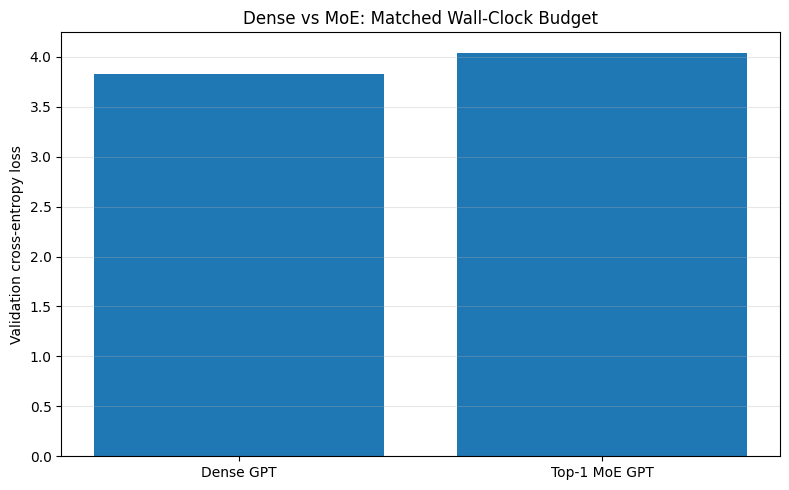

Dense steps: 1960
MoE steps: 1430
Dense validation loss: 3.8235
MoE validation loss: 4.0428


In [28]:

plt.figure(figsize=(8, 5))

plt.bar(
    ["Dense GPT", "Top-1 MoE GPT"],
    matched_results["validation_loss"]
)

plt.ylabel("Validation cross-entropy loss")
plt.title("Dense vs MoE: Matched Wall-Clock Budget")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Dense steps:", dense_matched_results["steps"])
print("MoE steps:", moe_matched_results["steps"])
print("Dense validation loss:",
      round(dense_matched_results["validation_loss"], 4))
print("MoE validation loss:",
      round(moe_matched_results["validation_loss"], 4))


In [29]:

import numpy as np
import pandas as pd
import torch

# Additional seeds; your existing seed-2026 run
# will be included in the final three-run summary.
additional_seeds = [2027, 2028]
repeat_results = []

for seed in additional_seeds:
    print(f"\n{'='*45}")
    print(f"Experiment seed: {seed}")
    print(f"{'='*45}")

    # Create fresh models for this seed.
    torch.manual_seed(seed)
    dense_trial = DenseGPT().to(device)

    torch.manual_seed(seed)
    moe_trial = MoEGPT().to(device)

    # Give both models the same nominal wall-clock budget.
    # Reset RNG before training each model.
    torch.manual_seed(seed + 10000)
    dense_result = train_for_time(
        dense_trial, is_moe=False,
        seconds=TIME_BUDGET_SECONDS
    )

    torch.manual_seed(seed + 10000)
    moe_result = train_for_time(
        moe_trial, is_moe=True,
        seconds=TIME_BUDGET_SECONDS
    )

    repeat_results.append({
        "seed": seed,
        "dense_val_loss": dense_result["validation_loss"],
        "moe_val_loss": moe_result["validation_loss"],
        "dense_tokens_per_second": dense_result["tokens_per_second"],
        "moe_tokens_per_second": moe_result["tokens_per_second"],
        "dense_steps": dense_result["steps"],
        "moe_steps": moe_result["steps"]
    })

    print("Dense validation loss:",
          round(dense_result["validation_loss"], 4))
    print("MoE validation loss:",
          round(moe_result["validation_loss"], 4))

repeat_df = pd.DataFrame(repeat_results)
print("\nAdditional runs:")
print(repeat_df.round(4).to_string(index=False))



Experiment seed: 2027
Dense validation loss: 3.8304
MoE validation loss: 4.0253

Experiment seed: 2028
Dense validation loss: 3.8483
MoE validation loss: 4.0852

Additional runs:
 seed  dense_val_loss  moe_val_loss  dense_tokens_per_second  moe_tokens_per_second  dense_steps  moe_steps
 2027          3.8304        4.0253               32986.1498             24254.7943         1940       1430
 2028          3.8483        4.0852               32677.5462             24336.8715         1930       1430


In [30]:

import numpy as np
import pandas as pd

dense_val_losses = [3.8235, 3.8304, 3.8483]
moe_val_losses = [4.0428, 4.0253, 4.0852]

dense_throughput = [
    33334.6093, 32986.1498, 32677.5462
]
moe_throughput = [
    24309.1085, 24254.7943, 24336.8715
]

summary = pd.DataFrame({
    "Metric": [
        "Validation loss (mean)",
        "Validation loss (std)",
        "Tokens/second (mean)",
        "Tokens/second (std)"
    ],
    "Dense GPT": [
        np.mean(dense_val_losses),
        np.std(dense_val_losses, ddof=1),
        np.mean(dense_throughput),
        np.std(dense_throughput, ddof=1)
    ],
    "Top-1 MoE GPT": [
        np.mean(moe_val_losses),
        np.std(moe_val_losses, ddof=1),
        np.mean(moe_throughput),
        np.std(moe_throughput, ddof=1)
    ]
})

print(summary.round(4).to_string(index=False))

print("\nMean validation-loss difference (MoE - Dense):",
      round(np.mean(moe_val_losses) -
            np.mean(dense_val_losses), 4))

print("Dense throughput advantage (%):",
      round((np.mean(dense_throughput) /
             np.mean(moe_throughput) - 1) * 100, 2))


                Metric  Dense GPT  Top-1 MoE GPT
Validation loss (mean)     3.8341         4.0511
 Validation loss (std)     0.0128         0.0308
  Tokens/second (mean) 32999.4351     24300.2581
   Tokens/second (std)   328.7330        41.7482

Mean validation-loss difference (MoE - Dense): 0.217
Dense throughput advantage (%): 35.8


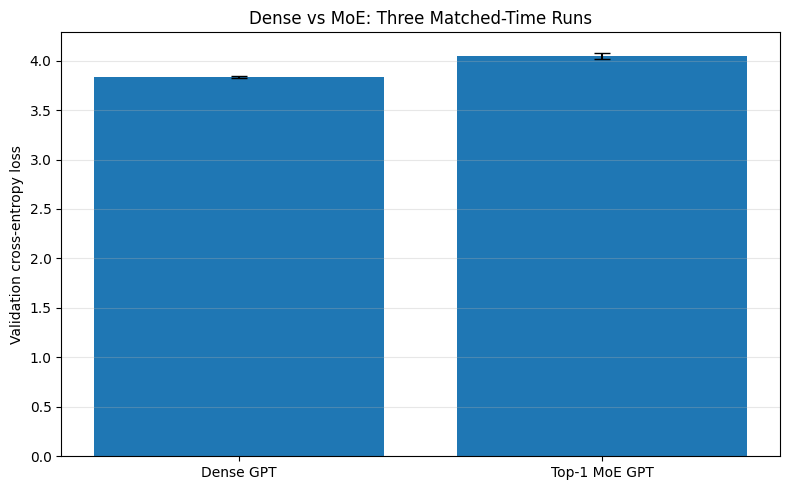

In [31]:

import matplotlib.pyplot as plt
import numpy as np

labels = ["Dense GPT", "Top-1 MoE GPT"]
means = [
    np.mean(dense_val_losses),
    np.mean(moe_val_losses)
]
stds = [
    np.std(dense_val_losses, ddof=1),
    np.std(moe_val_losses, ddof=1)
]

plt.figure(figsize=(8, 5))
plt.bar(labels, means, yerr=stds, capsize=6)
plt.ylabel("Validation cross-entropy loss")
plt.title("Dense vs MoE: Three Matched-Time Runs")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [32]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [33]:

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "Top1_MoE_TinyStories_Project"
)
os.makedirs(PROJECT_DIR, exist_ok=True)

# 1. Save the models trained in the original 500-step experiments.
torch.save(model.state_dict(),
           f"{PROJECT_DIR}/dense_gpt_500_steps.pt")
torch.save(moe_model.state_dict(),
           f"{PROJECT_DIR}/moe_gpt_500_steps.pt")

# 2. Save the original training histories.
pd.DataFrame(history).to_csv(
    f"{PROJECT_DIR}/dense_training_history.csv",
    index=False
)
pd.DataFrame(moe_history).to_csv(
    f"{PROJECT_DIR}/moe_training_history.csv",
    index=False
)

# 3. Save the expert utilisation data.
np.savetxt(
    f"{PROJECT_DIR}/expert_routed_counts.csv",
    routed_totals, delimiter=",",
    header="Expert 1,Expert 2,Expert 3,Expert 4",
    comments=""
)
np.savetxt(
    f"{PROJECT_DIR}/expert_accepted_counts.csv",
    accepted_totals, delimiter=",",
    header="Expert 1,Expert 2,Expert 3,Expert 4",
    comments=""
)

# 4. Save the original loss-curve figure.
plt.figure(figsize=(9, 5))
plt.plot(history["step"], history["train_loss"],
         marker="o", label="Dense train")
plt.plot(history["step"], history["val_loss"],
         marker="o", label="Dense validation")
plt.plot(moe_history["step"], moe_history["train_loss"],
         marker="s", label="MoE train")
plt.plot(moe_history["step"], moe_history["val_loss"],
         marker="s", label="MoE validation")
plt.xlabel("Training steps")
plt.ylabel("Cross-entropy loss")
plt.title("Dense GPT vs Top-1 MoE GPT")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    f"{PROJECT_DIR}/dense_vs_moe_loss.png",
    dpi=200, bbox_inches="tight"
)
plt.close()

# 5. Save the expert-utilisation figure.
plt.figure(figsize=(9, 5))
for layer_idx in range(num_layers):
    plt.plot(
        range(1, num_experts + 1),
        utilisation_pct[layer_idx],
        marker="o",
        label=f"Layer {layer_idx + 1}"
    )
plt.axhline(25, linestyle="--",
            label="Ideal equal share (25%)")
plt.xlabel("Expert")
plt.ylabel("Accepted tokens (%)")
plt.title("Expert Utilisation by MoE Layer")
plt.xticks(range(1, num_experts + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    f"{PROJECT_DIR}/expert_utilisation.png",
    dpi=200, bbox_inches="tight"
)
plt.close()

# 6. Save all three matched-time runs.
all_runs = pd.DataFrame([
    {
        "seed": 2026,
        "dense_val_loss": 3.8235,
        "moe_val_loss": 4.0428,
        "dense_tokens_per_second": 33334.6093,
        "moe_tokens_per_second": 24309.1085
    },
    *repeat_df.to_dict("records")
])
all_runs.to_csv(
    f"{PROJECT_DIR}/matched_time_runs.csv",
    index=False
)

# 7. Save a concise experimental summary.
summary = {
    "dataset": "TinyStories",
    "architecture": "Top-1 Mixture of Experts GPT",
    "num_experts_per_layer": 4,
    "moe_layers": 4,
    "capacity_factor": 1.25,
    "matched_time_budget_seconds": 60,
    "num_seeds": 3,
    "dense_mean_validation_loss": float(
        np.mean([3.8235, 3.8304, 3.8483])
    ),
    "moe_mean_validation_loss": float(
        np.mean([4.0428, 4.0253, 4.0852])
    ),
    "compute_comparison": "Matched wall-clock time, not exact FLOPs"
}
with open(f"{PROJECT_DIR}/experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Project files saved to:")
print(PROJECT_DIR)
print("\nFiles:")
for filename in sorted(os.listdir(PROJECT_DIR)):
    print("-", filename)


Project files saved to:
/content/drive/MyDrive/Top1_MoE_TinyStories_Project

Files:
- dense_gpt_500_steps.pt
- dense_training_history.csv
- dense_vs_moe_loss.png
- experiment_summary.json
- expert_accepted_counts.csv
- expert_routed_counts.csv
- expert_utilisation.png
- matched_time_runs.csv
- moe_gpt_500_steps.pt
- moe_training_history.csv


Device: cuda
Training steps per model: 500
Batch size: 8
Sequence length: 128
Training batches prepared: 500
Validation batches prepared: 20

Training Dense GPT...
Step 100/500 | LM loss: 6.0697
Step 200/500 | LM loss: 5.6497
Step 300/500 | LM loss: 5.2897
Step 400/500 | LM loss: 4.9759
Step 500/500 | LM loss: 4.7276

Training Top-1 MoE GPT...
Step 100/500 | LM loss: 6.0735
Step 200/500 | LM loss: 5.6600
Step 300/500 | LM loss: 5.3693
Step 400/500 | LM loss: 5.0009
Step 500/500 | LM loss: 4.7479

CONTROLLED COMPARISON RESULTS


,training_seconds,steps,training_tokens,mean_last_20_lm_loss,final_validation_lm_loss,validation_perplexity,mean_last_20_total_loss,mean_balance_loss
Dense GPT,15.3057,500,512000,4.7049,4.7631,117.1055,4.7049,0.0000
Top-1 MoE GPT,22.6162,500,512000,4.7489,4.8068,122.3395,4.7601,1.1984



Validation LM-loss difference (MoE - Dense): 0.0437
Training-token positions per model: 512000


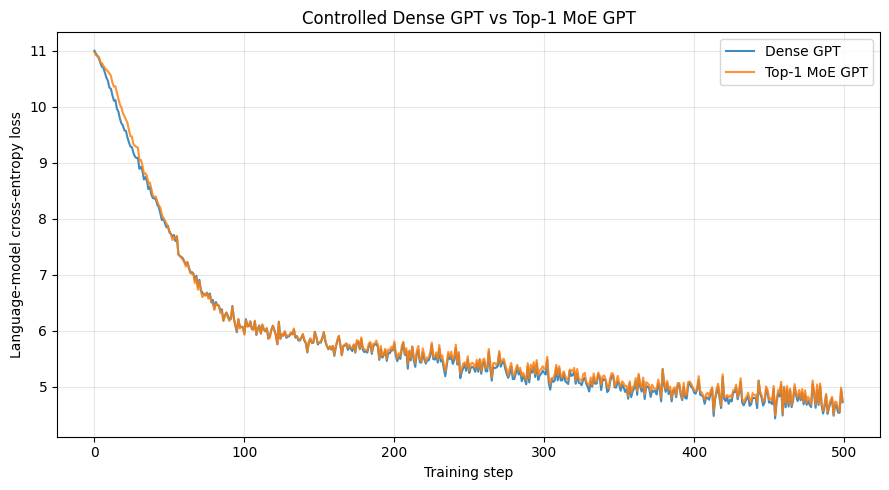


Saved:
- controlled_comparison_results.csv
- controlled_training_curves.csv
- dense_gpt_controlled.pt
- moe_gpt_controlled.pt


In [34]:

# STEP 1: Controlled Dense GPT vs Top-1 MoE comparison

import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Experiment configuration
# --------------------------------------------------
SEED = 2026
STEPS = 500
BATCH_SIZE = 8
AUX_COEFFICIENT = 0.01

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", device)
print("Training steps per model:", STEPS)
print("Batch size:", BATCH_SIZE)
print("Sequence length:", block_size)

# --------------------------------------------------
# 2. Create identical training batches for both models
# --------------------------------------------------
torch.manual_seed(SEED + 1)

train_batches = [
    get_batch_from(train_data, batch_size=BATCH_SIZE)
    for _ in range(STEPS)
]

# Fixed validation batches: both models see exactly
# the same validation examples.
torch.manual_seed(SEED + 2)

fixed_val_batches = [
    get_batch_from(val_data, batch_size=BATCH_SIZE)
    for _ in range(20)
]

print("Training batches prepared:", len(train_batches))
print("Validation batches prepared:", len(fixed_val_batches))

# --------------------------------------------------
# 3. Fixed validation evaluation
#    Report LM cross-entropy only
# --------------------------------------------------
@torch.no_grad()
def evaluate_fixed(model_to_test, is_moe):
    model_to_test.eval()
    losses = []

    for xb, yb in fixed_val_batches:
        if is_moe:
            _, lm_loss, _, _ = model_to_test(xb, yb)
        else:
            _, lm_loss = model_to_test(xb, yb)

        losses.append(lm_loss.item())

    return float(np.mean(losses))

# --------------------------------------------------
# 4. Training function
# --------------------------------------------------
def train_controlled(model_to_train, is_moe):
    optimizer = torch.optim.AdamW(
        model_to_train.parameters(),
        lr=3e-4
    )

    lm_losses = []
    total_losses = []
    balance_losses = []

    model_to_train.train()

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for step, (xb, yb) in enumerate(train_batches, start=1):
        optimizer.zero_grad(set_to_none=True)

        if is_moe:
            _, lm_loss, aux_loss, _ = model_to_train(xb, yb)
            total_loss = lm_loss + AUX_COEFFICIENT * aux_loss
            balance_losses.append(aux_loss.item())
        else:
            _, lm_loss = model_to_train(xb, yb)
            total_loss = lm_loss

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_to_train.parameters(), 1.0
        )

        optimizer.step()

        # Store language-model loss separately.
        lm_losses.append(lm_loss.item())
        total_losses.append(total_loss.item())

        if step % 100 == 0:
            print(
                f"Step {step}/{STEPS} | "
                f"LM loss: {lm_loss.item():.4f}"
            )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    val_loss = evaluate_fixed(model_to_train, is_moe)

    return {
        "training_seconds": elapsed,
        "steps": STEPS,
        "training_tokens": STEPS * BATCH_SIZE * block_size,
        "mean_last_20_lm_loss": float(np.mean(lm_losses[-20:])),
        "final_validation_lm_loss": val_loss,
        "validation_perplexity": float(np.exp(val_loss)),
        "mean_last_20_total_loss": float(np.mean(total_losses[-20:])),
        "mean_balance_loss": (
            float(np.mean(balance_losses))
            if is_moe else 0.0
        ),
        "lm_loss_history": lm_losses
    }

# --------------------------------------------------
# 5. Train fresh models
# --------------------------------------------------
torch.manual_seed(SEED)
dense_fair = DenseGPT().to(device)

torch.manual_seed(SEED)
moe_fair = MoEGPT().to(device)

print("\nTraining Dense GPT...")
dense_result = train_controlled(
    dense_fair, is_moe=False
)

print("\nTraining Top-1 MoE GPT...")
moe_result = train_controlled(
    moe_fair, is_moe=True
)

# --------------------------------------------------
# 6. Results table
# --------------------------------------------------
results_df = pd.DataFrame(
    [
        {k: v for k, v in dense_result.items()
         if k != "lm_loss_history"},
        {k: v for k, v in moe_result.items()
         if k != "lm_loss_history"}
    ],
    index=["Dense GPT", "Top-1 MoE GPT"]
)

print("\nCONTROLLED COMPARISON RESULTS")
display(results_df.round(4))

print(
    "\nValidation LM-loss difference (MoE - Dense):",
    round(
        moe_result["final_validation_lm_loss"]
        - dense_result["final_validation_lm_loss"],
        4
    )
)

print(
    "Training-token positions per model:",
    STEPS * BATCH_SIZE * block_size
)

# --------------------------------------------------
# 7. Plot training language-model losses
# --------------------------------------------------
plt.figure(figsize=(9, 5))

plt.plot(
    dense_result["lm_loss_history"],
    label="Dense GPT",
    alpha=0.85
)

plt.plot(
    moe_result["lm_loss_history"],
    label="Top-1 MoE GPT",
    alpha=0.85
)

plt.xlabel("Training step")
plt.ylabel("Language-model cross-entropy loss")
plt.title("Controlled Dense GPT vs Top-1 MoE GPT")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Save results for the final report
# --------------------------------------------------
results_df.to_csv("controlled_comparison_results.csv")

pd.DataFrame({
    "step": range(1, STEPS + 1),
    "dense_lm_loss": dense_result["lm_loss_history"],
    "moe_lm_loss": moe_result["lm_loss_history"]
}).to_csv("controlled_training_curves.csv", index=False)

torch.save(dense_fair.state_dict(), "dense_gpt_controlled.pt")
torch.save(moe_fair.state_dict(), "moe_gpt_controlled.pt")

print("\nSaved:")
print("- controlled_comparison_results.csv")
print("- controlled_training_curves.csv")
print("- dense_gpt_controlled.pt")
print("- moe_gpt_controlled.pt")


In [35]:

# STEP 2: Inspect expert utilisation after controlled training

# Run a fresh diagnostic batch.
moe_fair.eval()

torch.manual_seed(2030)
xb, yb = get_batch_from(
    val_data,
    batch_size=8
)

with torch.no_grad():
    output = moe_fair(xb, yb)

print("MoE forward pass completed.")
print("Output tuple length:", len(output))
print("Check the model's stored routing statistics next.")


MoE forward pass completed.
Output tuple length: 4
Check the model's stored routing statistics next.


In [36]:

# Inspect the actual MoE layers and their stored statistics

print("MoE model structure:\n")
for name, module in moe_fair.named_modules():
    if any(word in name.lower() for word in
           ["moe", "expert", "router", "feedforward", "ffn"]):
        print(f"\nModule: {name or '<root>'}")
        print("Class:", type(module).__name__)

        # Show relevant attributes without printing tensor contents.
        for attr in dir(module):
            if any(word in attr.lower() for word in [
                "expert", "router", "route", "capacity",
                "drop", "token", "count", "load", "stat"
            ]):
                try:
                    value = getattr(module, attr)
                    if not callable(value) and not attr.startswith("__"):
                        if isinstance(value, torch.Tensor):
                            print(
                                f"  {attr}: Tensor "
                                f"shape={tuple(value.shape)}"
                            )
                        elif isinstance(value, (int, float, str, bool, list, tuple)):
                            print(f"  {attr}: {value}")
                except Exception:
                    pass


MoE model structure:


Module: blocks.0.moe_ffn
Class: MoEFeedForward
  capacity_factor: 1.25
  num_experts: 4

Module: blocks.0.moe_ffn.router
Class: Linear

Module: blocks.0.moe_ffn.experts
Class: ModuleList

Module: blocks.0.moe_ffn.experts.0
Class: Sequential

Module: blocks.0.moe_ffn.experts.0.0
Class: Linear

Module: blocks.0.moe_ffn.experts.0.1
Class: GELU

Module: blocks.0.moe_ffn.experts.0.2
Class: Linear

Module: blocks.0.moe_ffn.experts.0.3
Class: Dropout

Module: blocks.0.moe_ffn.experts.1
Class: Sequential

Module: blocks.0.moe_ffn.experts.1.0
Class: Linear

Module: blocks.0.moe_ffn.experts.1.1
Class: GELU

Module: blocks.0.moe_ffn.experts.1.2
Class: Linear

Module: blocks.0.moe_ffn.experts.1.3
Class: Dropout

Module: blocks.0.moe_ffn.experts.2
Class: Sequential

Module: blocks.0.moe_ffn.experts.2.0
Class: Linear

Module: blocks.0.moe_ffn.experts.2.1
Class: GELU

Module: blocks.0.moe_ffn.experts.2.2
Class: Linear

Module: blocks.0.moe_ffn.experts.2.3
Class: Dropout

Module

In [37]:

import inspect

# Print the MoE layer implementation used by your model.
for name, module in moe_fair.named_modules():
    if "moe_ffn" in name.lower() and not any(
        part in name.lower() for part in ["experts."]
    ):
        print("\nMODULE:", name)
        print("CLASS:", type(module).__name__)

        try:
            print(inspect.getsource(type(module).forward))
        except (OSError, TypeError):
            print("Source unavailable for this module.")



MODULE: blocks.0.moe_ffn
CLASS: MoEFeedForward
    def forward(self, x):
        # x shape: [batch, sequence, embedding]
        B, T, D = x.shape
        tokens = x.reshape(B * T, D)
        total_tokens = tokens.size(0)
        N = self.num_experts

        # Router probabilities for every token.
        router_logits = self.router(tokens).float()
        router_probs = F.softmax(router_logits, dim=-1)

        # Top-1 routing: one expert per token.
        gates, expert_ids = router_probs.max(dim=-1)

        # Capacity limit for each expert.
        capacity = max(
            1,
            math.ceil(
                (total_tokens / N) * self.capacity_factor
            )
        )

        # Encourage balanced routing.
        importance = router_probs.mean(dim=0)

        fraction_routed = F.one_hot(
            expert_ids, num_classes=N
        ).float().mean(dim=0)

        balance_loss = N * torch.sum(
            importance * fraction_routed
        )

        # Initially, 

EXPERT ROUTING STATISTICS


,Layer,Expert,Routed tokens,Accepted tokens,Dropped tokens,Capacity,Routed (%),Accepted (%)
0,1,1,335,320,15,320,32.71,31.25
1,1,2,200,200,0,320,19.53,19.53
2,1,3,165,165,0,320,16.11,16.11
3,1,4,324,320,4,320,31.64,31.25
4,2,1,78,78,0,320,7.62,7.62
5,2,2,389,320,69,320,37.99,31.25
6,2,3,151,151,0,320,14.75,14.75
7,2,4,406,320,86,320,39.65,31.25
8,3,1,173,173,0,320,16.89,16.89
9,3,2,181,181,0,320,17.68,17.68


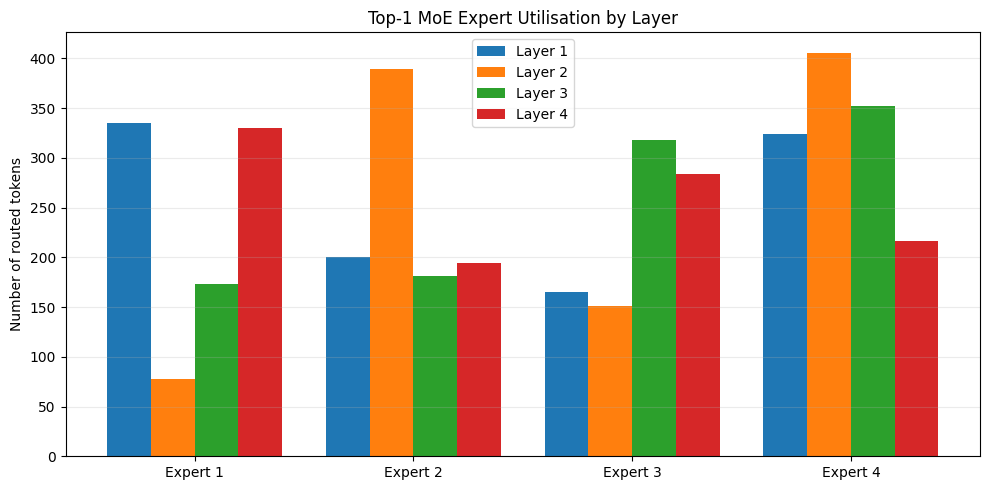

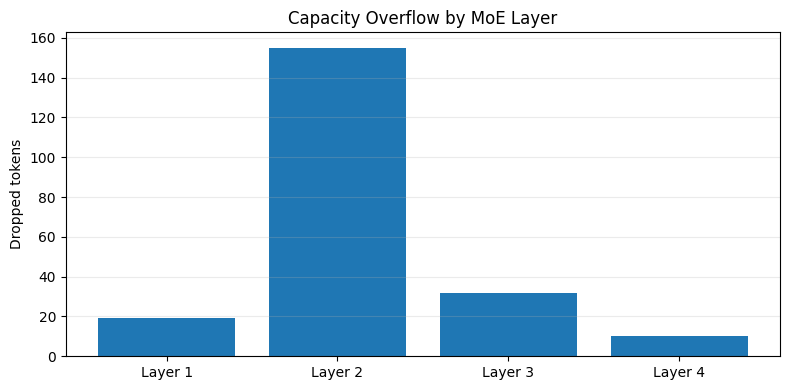

Saved:
- expert_utilisation_by_layer.png
- moe_dropped_tokens.png
- expert_routing_statistics.csv


In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Evaluate one fixed validation batch.
moe_fair.eval()
torch.manual_seed(2030)

xb, yb = get_batch_from(val_data, batch_size=8)

# Collect the stats returned by each MoE FFN.
routing_stats = []

def capture_moe_stats(module, inputs, output):
    # MoEFeedForward returns (output, balance_loss, stats).
    stats = output[2]
    routing_stats.append({
        "capacity": stats["capacity"],
        "routed": stats["routed_counts"].cpu().numpy(),
        "accepted": stats["accepted_counts"].cpu().numpy(),
        "dropped": int(stats["dropped_tokens"].item()),
        "total_tokens": stats["total_tokens"]
    })

handles = []
for name, module in moe_fair.named_modules():
    if type(module).__name__ == "MoEFeedForward":
        handles.append(
            module.register_forward_hook(capture_moe_stats)
        )

with torch.no_grad():
    _ = moe_fair(xb, yb)

# Always remove hooks after the forward pass.
for handle in handles:
    handle.remove()

if len(routing_stats) == 0:
    raise RuntimeError("No MoE routing statistics were captured.")

# Create a detailed table.
rows = []
for layer_idx, stats in enumerate(routing_stats, start=1):
    for expert_idx, (routed, accepted) in enumerate(
        zip(stats["routed"], stats["accepted"]), start=1
    ):
        rows.append({
            "Layer": layer_idx,
            "Expert": expert_idx,
            "Routed tokens": int(routed),
            "Accepted tokens": int(accepted),
            "Dropped tokens": int(routed - accepted),
            "Capacity": stats["capacity"],
            "Routed (%)": 100 * routed / stats["total_tokens"],
            "Accepted (%)": 100 * accepted / stats["total_tokens"]
        })

routing_df = pd.DataFrame(rows)

print("EXPERT ROUTING STATISTICS")
display(routing_df.round(2))

# Plot routed-token distribution for each layer.
num_layers = len(routing_stats)
num_experts = len(routing_stats[0]["routed"])
x = np.arange(num_experts)
width = 0.8 / num_layers

plt.figure(figsize=(10, 5))

for layer_idx, stats in enumerate(routing_stats):
    routed = stats["routed"]
    offset = (layer_idx - (num_layers - 1) / 2) * width

    plt.bar(
        x + offset,
        routed,
        width=width,
        label=f"Layer {layer_idx + 1}"
    )

plt.xticks(x, [f"Expert {i+1}" for i in range(num_experts)])
plt.ylabel("Number of routed tokens")
plt.title("Top-1 MoE Expert Utilisation by Layer")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("expert_utilisation_by_layer.png", dpi=200)
plt.show()

# Plot dropped tokens per layer.
dropped_by_layer = [s["dropped"] for s in routing_stats]

plt.figure(figsize=(8, 4))
plt.bar(
    [f"Layer {i+1}" for i in range(num_layers)],
    dropped_by_layer
)
plt.ylabel("Dropped tokens")
plt.title("Capacity Overflow by MoE Layer")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("moe_dropped_tokens.png", dpi=200)
plt.show()

routing_df.to_csv("expert_routing_statistics.csv", index=False)

print("Saved:")
print("- expert_utilisation_by_layer.png")
print("- moe_dropped_tokens.png")
print("- expert_routing_statistics.csv")


In [39]:

# Verify capacity and dropped-token rates for each MoE layer

for i, stats in enumerate(routing_stats, start=1):
    routed = np.asarray(stats["routed"])
    accepted = np.asarray(stats["accepted"])

    total_routed = int(routed.sum())
    total_accepted = int(accepted.sum())
    dropped = total_routed - total_accepted
    total_tokens = int(stats["total_tokens"])

    print(f"\nLayer {i}")
    print("Total token positions:", total_tokens)
    print("Capacity per expert:", stats["capacity"])
    print("Routed tokens:", total_routed)
    print("Accepted tokens:", total_accepted)
    print("Dropped tokens:", dropped)
    print(
        "Drop rate (%):",
        round(100 * dropped / max(total_routed, 1), 2)
    )

    assert np.all(accepted <= stats["capacity"]), (
        "An expert accepted more tokens than its capacity."
    )
    assert total_routed == total_accepted + dropped



Layer 1
Total token positions: 1024
Capacity per expert: 320
Routed tokens: 1024
Accepted tokens: 1005
Dropped tokens: 19
Drop rate (%): 1.86

Layer 2
Total token positions: 1024
Capacity per expert: 320
Routed tokens: 1024
Accepted tokens: 869
Dropped tokens: 155
Drop rate (%): 15.14

Layer 3
Total token positions: 1024
Capacity per expert: 320
Routed tokens: 1024
Accepted tokens: 992
Dropped tokens: 32
Drop rate (%): 3.12

Layer 4
Total token positions: 1024
Capacity per expert: 320
Routed tokens: 1024
Accepted tokens: 1014
Dropped tokens: 10
Drop rate (%): 0.98


In [40]:

# Compare routed-token distribution and capacity per expert
# for the current diagnostic batch.

for i, stats in enumerate(routing_stats, start=1):
    routed = np.asarray(stats["routed"])
    accepted = np.asarray(stats["accepted"])
    capacity = stats["capacity"]

    print(f"\nLayer {i}")
    print("Routed per expert:  ", routed.tolist())
    print("Accepted per expert:", accepted.tolist())
    print("Capacity per expert:", capacity)
    print(
        "Expert load imbalance (max - min):",
        int(routed.max() - routed.min())
    )
    print(
        "Experts at capacity:",
        int(np.sum(accepted >= capacity)),
        "out of",
        len(accepted)
    )



Layer 1
Routed per expert:   [335, 200, 165, 324]
Accepted per expert: [320, 200, 165, 320]
Capacity per expert: 320
Expert load imbalance (max - min): 170
Experts at capacity: 2 out of 4

Layer 2
Routed per expert:   [78, 389, 151, 406]
Accepted per expert: [78, 320, 151, 320]
Capacity per expert: 320
Expert load imbalance (max - min): 328
Experts at capacity: 2 out of 4

Layer 3
Routed per expert:   [173, 181, 318, 352]
Accepted per expert: [173, 181, 318, 320]
Capacity per expert: 320
Expert load imbalance (max - min): 179
Experts at capacity: 1 out of 4

Layer 4
Routed per expert:   [330, 194, 284, 216]
Accepted per expert: [320, 194, 284, 216]
Capacity per expert: 320
Expert load imbalance (max - min): 136
Experts at capacity: 1 out of 4


In [41]:

# Inspect the MoE forward method and the balancing-loss calculation.

import inspect

for name, module in moe_fair.named_modules():
    cls_name = type(module).__name__

    if cls_name == "MoEFeedForward":
        print(f"\n--- {name}: forward() ---")
        print(inspect.getsource(type(module).forward))

        # Inspect class methods related to routing or balancing.
        for method_name in dir(type(module)):
            if any(k in method_name.lower()
                   for k in ["balance", "router", "route"]):
                method = getattr(type(module), method_name)
                if callable(method):
                    try:
                        print(f"\n--- {method_name}() ---")
                        print(inspect.getsource(method))
                    except (OSError, TypeError):
                        pass



--- blocks.0.moe_ffn: forward() ---
    def forward(self, x):
        # x shape: [batch, sequence, embedding]
        B, T, D = x.shape
        tokens = x.reshape(B * T, D)
        total_tokens = tokens.size(0)
        N = self.num_experts

        # Router probabilities for every token.
        router_logits = self.router(tokens).float()
        router_probs = F.softmax(router_logits, dim=-1)

        # Top-1 routing: one expert per token.
        gates, expert_ids = router_probs.max(dim=-1)

        # Capacity limit for each expert.
        capacity = max(
            1,
            math.ceil(
                (total_tokens / N) * self.capacity_factor
            )
        )

        # Encourage balanced routing.
        importance = router_probs.mean(dim=0)

        fraction_routed = F.one_hot(
            expert_ids, num_classes=N
        ).float().mean(dim=0)

        balance_loss = N * torch.sum(
            importance * fraction_routed
        )

        # Initially, outputs for

In [42]:

import inspect

for name, module in moe_fair.named_modules():
    if type(module).__name__ == "MoEFeedForward":
        source = inspect.getsource(type(module).forward)

        print(f"\n===== {name} =====")
        for line_no, line in enumerate(source.splitlines(), start=1):
            if any(word in line.lower() for word in [
                "router", "softmax", "topk", "argmax",
                "balance", "prob", "density", "expert_mask",
                "capacity", "aux"
            ]):
                start = max(0, line_no - 3)
                end = min(len(source.splitlines()), line_no + 2)

                lines = source.splitlines()
                print("\n".join(
                    f"{j+1}: {lines[j]}"
                    for j in range(start, end)
                ))
                print("---")



===== blocks.0.moe_ffn =====
6:         N = self.num_experts
7: 
8:         # Router probabilities for every token.
9:         router_logits = self.router(tokens).float()
10:         router_probs = F.softmax(router_logits, dim=-1)
---
7: 
8:         # Router probabilities for every token.
9:         router_logits = self.router(tokens).float()
10:         router_probs = F.softmax(router_logits, dim=-1)
11: 
---
8:         # Router probabilities for every token.
9:         router_logits = self.router(tokens).float()
10:         router_probs = F.softmax(router_logits, dim=-1)
11: 
12:         # Top-1 routing: one expert per token.
---
11: 
12:         # Top-1 routing: one expert per token.
13:         gates, expert_ids = router_probs.max(dim=-1)
14: 
15:         # Capacity limit for each expert.
---
13:         gates, expert_ids = router_probs.max(dim=-1)
14: 
15:         # Capacity limit for each expert.
16:         capacity = max(
17:             1,
---
14: 
15:         # Capacity limi

In [43]:

# STEP 3: Aggregate expert routing over 20 validation batches

import numpy as np
import pandas as pd
import torch

moe_fair.eval()
torch.manual_seed(2031)

num_batches = 20
all_batch_stats = []

def collect_routing_stats(module, inputs, output):
    # MoEFeedForward returns (output, balance_loss, stats)
    stats = output[2]
    all_batch_stats.append({
        "capacity": int(stats["capacity"]),
        "routed": stats["routed_counts"].detach().cpu().numpy().copy(),
        "accepted": stats["accepted_counts"].detach().cpu().numpy().copy(),
        "dropped": int(stats["dropped_tokens"].item()),
        "total_tokens": int(stats["total_tokens"])
    })

handles = []
for name, module in moe_fair.named_modules():
    if type(module).__name__ == "MoEFeedForward":
        handles.append(
            module.register_forward_hook(collect_routing_stats)
        )

try:
    with torch.no_grad():
        for batch_idx in range(num_batches):
            xb, yb = get_batch_from(val_data, batch_size=8)
            _ = moe_fair(xb, yb)
finally:
    for handle in handles:
        handle.remove()

num_layers = len(handles)
if len(all_batch_stats) != num_batches * num_layers:
    raise RuntimeError(
        f"Expected {num_batches * num_layers} records, "
        f"got {len(all_batch_stats)}."
    )

rows = []
for layer_idx in range(num_layers):
    layer_stats = all_batch_stats[
        layer_idx::num_layers
    ]

    routed = np.stack([s["routed"] for s in layer_stats])
    accepted = np.stack([s["accepted"] for s in layer_stats])

    total_routed = int(routed.sum())
    total_accepted = int(accepted.sum())
    total_dropped = total_routed - total_accepted

    rows.append({
        "Layer": layer_idx + 1,
        "Batches": num_batches,
        "Mean routed/expert/batch": round(routed.mean(axis=0).mean(), 2),
        "Mean expert load imbalance": round(
            np.mean(routed.max(axis=1) - routed.min(axis=1)), 2
        ),
        "Total routed": total_routed,
        "Total accepted": total_accepted,
        "Total dropped": total_dropped,
        "Aggregate drop rate (%)": round(
            100 * total_dropped / max(total_routed, 1), 2
        )
    })

aggregate_df = pd.DataFrame(rows)
display(aggregate_df)

aggregate_df.to_csv(
    "routing_aggregate_20_batches.csv",
    index=False
)

print("Saved routing_aggregate_20_batches.csv")


,Layer,Batches,Mean routed/expert/batch,Mean expert load imbalance,Total routed,Total accepted,Total dropped,Aggregate drop rate (%)
0,1,20,256.0,167.35,20480,20267,213,1.04
1,2,20,256.0,352.20,20480,17331,3149,15.38
2,3,20,256.0,188.20,20480,19642,838,4.09
3,4,20,256.0,144.85,20480,20223,257,1.25


Saved routing_aggregate_20_batches.csv


In [44]:

# Inspect capacity-factor configuration without changing the model.

for name, module in moe_fair.named_modules():
    if type(module).__name__ == "MoEFeedForward":
        print(f"\nModule: {name}")

        for attr in dir(module):
            if "capacity" in attr.lower():
                try:
                    value = getattr(module, attr)
                    if not callable(value):
                        print(f"{attr} = {value}")
                except Exception:
                    pass



Module: blocks.0.moe_ffn
capacity_factor = 1.25

Module: blocks.1.moe_ffn
capacity_factor = 1.25

Module: blocks.2.moe_ffn
capacity_factor = 1.25

Module: blocks.3.moe_ffn
capacity_factor = 1.25


In [45]:

# STEP 4A: Capacity-factor ablation (1.25 vs 1.5)
# The original trained model and its weights are preserved.

import numpy as np
import pandas as pd
import torch

moe_fair.eval()

moe_layers = [
    module for module in moe_fair.modules()
    if type(module).__name__ == "MoEFeedForward"
]

original_factors = [m.capacity_factor for m in moe_layers]

# Pre-generate the same validation batches for both settings.
torch.manual_seed(2032)
diagnostic_batches = [
    get_batch_from(val_data, batch_size=8)
    for _ in range(20)
]

def measure_capacity_factor(factor):
    records = []

    for layer in moe_layers:
        layer.capacity_factor = factor

    def capture(module, inputs, output):
        stats = output[2]
        records.append({
            "routed": stats["routed_counts"].detach().cpu().numpy().copy(),
            "accepted": stats["accepted_counts"].detach().cpu().numpy().copy(),
            "dropped": int(stats["dropped_tokens"].item()),
            "capacity": int(stats["capacity"])
        })

    handles = [
        layer.register_forward_hook(capture)
        for layer in moe_layers
    ]

    try:
        with torch.no_grad():
            for xb, yb in diagnostic_batches:
                _ = moe_fair(xb, yb)
    finally:
        for handle in handles:
            handle.remove()

    rows = []
    num_layers = len(moe_layers)

    for i in range(num_layers):
        layer_records = records[i::num_layers]
        routed = np.stack([r["routed"] for r in layer_records])
        accepted = np.stack([r["accepted"] for r in layer_records])

        total_routed = int(routed.sum())
        total_accepted = int(accepted.sum())

        rows.append({
            "Capacity factor": factor,
            "Layer": i + 1,
            "Capacity/expert": layer_records[0]["capacity"],
            "Total routed": total_routed,
            "Total accepted": total_accepted,
            "Total dropped": total_routed - total_accepted,
            "Drop rate (%)": round(
                100 * (total_routed - total_accepted)
                / max(total_routed, 1), 2
            )
        })

    return rows

try:
    rows_125 = measure_capacity_factor(1.25)
    rows_150 = measure_capacity_factor(1.5)
finally:
    for layer, original in zip(moe_layers, original_factors):
        layer.capacity_factor = original

capacity_df = pd.DataFrame(rows_125 + rows_150)
display(capacity_df)

print("Original capacity factors restored:",
      [m.capacity_factor for m in moe_layers])

capacity_df.to_csv("capacity_factor_ablation.csv", index=False)
print("Saved capacity_factor_ablation.csv")


,Capacity factor,Layer,Capacity/expert,Total routed,Total accepted,Total dropped,Drop rate (%)
0,1.25,1,320,20480,20158,322,1.57
1,1.25,2,320,20480,17245,3235,15.80
2,1.25,3,320,20480,19715,765,3.74
3,1.25,4,320,20480,20182,298,1.46
4,1.50,1,384,20480,20480,0,0.00
5,1.50,2,384,20480,19601,879,4.29
6,1.50,3,384,20480,20480,0,0.00
7,1.50,4,384,20480,20480,0,0.00


Original capacity factors restored: [1.25, 1.25, 1.25, 1.25]
Saved capacity_factor_ablation.csv


In [46]:

# STEP 5: Compare validation loss at capacity factors 1.25 and 1.5
# Evaluation only: no training and no weight updates.

import numpy as np
import pandas as pd
import torch

moe_fair.eval()

moe_layers = [
    module for module in moe_fair.modules()
    if type(module).__name__ == "MoEFeedForward"
]
original_factors = [m.capacity_factor for m in moe_layers]

# Reuse the same diagnostic validation batches.
eval_rows = []

try:
    for factor in [1.25, 1.5]:
        for layer in moe_layers:
            layer.capacity_factor = factor

        lm_losses = []
        aux_losses = []

        with torch.no_grad():
            for xb, yb in diagnostic_batches:
                _, lm_loss, aux_loss, _ = moe_fair(xb, yb)
                lm_losses.append(float(lm_loss.item()))
                aux_losses.append(float(aux_loss.item()))

        eval_rows.append({
            "Capacity factor": factor,
            "Mean validation LM loss": np.mean(lm_losses),
            "Mean validation auxiliary loss": np.mean(aux_losses),
            "Validation perplexity": np.exp(np.mean(lm_losses))
        })
finally:
    for layer, original in zip(moe_layers, original_factors):
        layer.capacity_factor = original

eval_df = pd.DataFrame(eval_rows)
display(eval_df.round(4))

eval_df.to_csv("capacity_factor_validation_comparison.csv", index=False)
print("Original capacity factors restored.")
print("Saved capacity_factor_validation_comparison.csv")


,Capacity factor,Mean validation LM loss,Mean validation auxiliary loss,Validation perplexity
0,1.25,4.8369,1.1070,126.0824
1,1.50,4.8222,1.1068,124.2386


Original capacity factors restored.
Saved capacity_factor_validation_comparison.csv


In [47]:

import torch
import torch.nn as nn

# Find the models currently defined in the notebook.
model_names = ["dense_model", "dense", "moe_fair", "moe_model", "moe"]

for name in model_names:
    model = globals().get(name)
    if isinstance(model, nn.Module):
        print(f"\n{'=' * 55}")
        print(f"MODEL: {name}")
        print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

        print("\nLinear layers (input features -> output features):")
        for module_name, module in model.named_modules():
            if isinstance(module, nn.Linear):
                print(
                    f"{module_name}: "
                    f"{module.in_features} -> {module.out_features}"
                )



MODEL: moe_fair
Parameters: 15,308,369

Linear layers (input features -> output features):
blocks.0.attn.attention.out_proj: 128 -> 128
blocks.0.moe_ffn.router: 128 -> 4
blocks.0.moe_ffn.experts.0.0: 128 -> 512
blocks.0.moe_ffn.experts.0.2: 512 -> 128
blocks.0.moe_ffn.experts.1.0: 128 -> 512
blocks.0.moe_ffn.experts.1.2: 512 -> 128
blocks.0.moe_ffn.experts.2.0: 128 -> 512
blocks.0.moe_ffn.experts.2.2: 512 -> 128
blocks.0.moe_ffn.experts.3.0: 128 -> 512
blocks.0.moe_ffn.experts.3.2: 512 -> 128
blocks.1.attn.attention.out_proj: 128 -> 128
blocks.1.moe_ffn.router: 128 -> 4
blocks.1.moe_ffn.experts.0.0: 128 -> 512
blocks.1.moe_ffn.experts.0.2: 512 -> 128
blocks.1.moe_ffn.experts.1.0: 128 -> 512
blocks.1.moe_ffn.experts.1.2: 512 -> 128
blocks.1.moe_ffn.experts.2.0: 128 -> 512
blocks.1.moe_ffn.experts.2.2: 512 -> 128
blocks.1.moe_ffn.experts.3.0: 128 -> 512
blocks.1.moe_ffn.experts.3.2: 512 -> 128
blocks.2.attn.attention.out_proj: 128 -> 128
blocks.2.moe_ffn.router: 128 -> 4
blocks.2.moe_ff

In [48]:

import torch.nn as nn

seen = set()

for name, model in list(globals().items()):
    if not isinstance(model, nn.Module):
        continue
    if not any(word in name.lower() for word in ("dense", "moe")):
        continue
    if id(model) in seen:
        continue
    seen.add(id(model))

    print(f"\nMODEL: {name}")
    print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

    for layer_name, layer in model.named_modules():
        if isinstance(layer, nn.Linear) and (
            "ffn" in layer_name.lower()
            or "expert" in layer_name.lower()
        ):
            print(
                f"{layer_name}: "
                f"{layer.in_features} -> {layer.out_features}"
            )



MODEL: moe_ffn
Parameters: 527,360
experts.0.0: 128 -> 512
experts.0.2: 512 -> 128
experts.1.0: 128 -> 512
experts.1.2: 512 -> 128
experts.2.0: 128 -> 512
experts.2.2: 512 -> 128
experts.3.0: 128 -> 512
experts.3.2: 512 -> 128

MODEL: moe_model
Parameters: 15,308,369
blocks.0.moe_ffn.router: 128 -> 4
blocks.0.moe_ffn.experts.0.0: 128 -> 512
blocks.0.moe_ffn.experts.0.2: 512 -> 128
blocks.0.moe_ffn.experts.1.0: 128 -> 512
blocks.0.moe_ffn.experts.1.2: 512 -> 128
blocks.0.moe_ffn.experts.2.0: 128 -> 512
blocks.0.moe_ffn.experts.2.2: 512 -> 128
blocks.0.moe_ffn.experts.3.0: 128 -> 512
blocks.0.moe_ffn.experts.3.2: 512 -> 128
blocks.1.moe_ffn.router: 128 -> 4
blocks.1.moe_ffn.experts.0.0: 128 -> 512
blocks.1.moe_ffn.experts.0.2: 512 -> 128
blocks.1.moe_ffn.experts.1.0: 128 -> 512
blocks.1.moe_ffn.experts.1.2: 512 -> 128
blocks.1.moe_ffn.experts.2.0: 128 -> 512
blocks.1.moe_ffn.experts.2.2: 512 -> 128
blocks.1.moe_ffn.experts.3.0: 128 -> 512
blocks.1.moe_ffn.experts.3.2: 512 -> 128
blocks.